<a href="https://colab.research.google.com/github/liya08-creator/credit-risk-analysis/blob/main/notebooks/03_eda_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("credit_card_clean.csv")

target = "default_next_month"
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

print(df.shape)
print(df[target].value_counts())
print("Default rate:", round(df[target].mean(), 4))

(30000, 28)
default_next_month
0    23364
1     6636
Name: count, dtype: int64
Default rate: 0.2212


In [2]:
#  demographic summary tables

# Age: numeric summary
print("AGE summary")
print(df["AGE"].describe().round(1))
print("Skewness:", round(df["AGE"].skew(), 2))

# Categorical demographics: count and percentage
for col in ["SEX_label", "EDUCATION_label", "MARRIAGE_label"]:
    counts = df[col].value_counts()
    summary = pd.DataFrame({
        "count": counts,
        "percent": (100 * counts / len(df)).round(1)
    })
    print(f"\n{col}")
    print(summary)

AGE summary
count    30000.0
mean        35.5
std          9.2
min         21.0
25%         28.0
50%         34.0
75%         41.0
max         79.0
Name: AGE, dtype: float64
Skewness: 0.73

SEX_label
           count  percent
SEX_label                
Female     18112     60.4
Male       11888     39.6

EDUCATION_label
                 count  percent
EDUCATION_label                
University       14030     46.8
Graduate school  10585     35.3
High school       4917     16.4
Others             468      1.6

MARRIAGE_label
                count  percent
MARRIAGE_label                
Single          15964     53.2
Married         13659     45.5
Others            323      1.1
Unknown            54      0.2


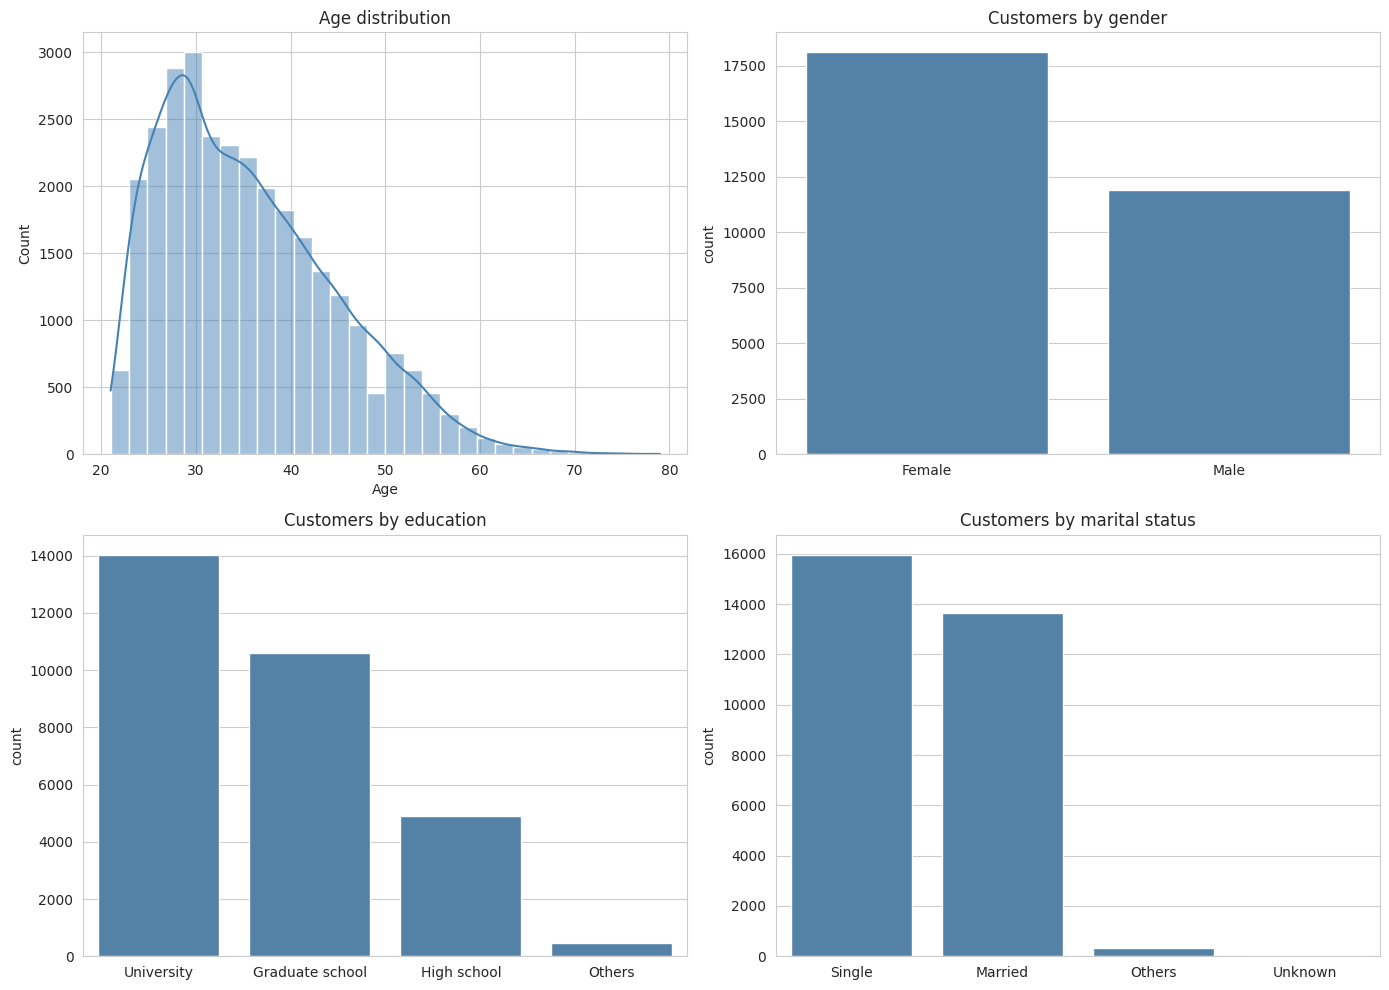

In [3]:
#  demographic charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Age distribution
sns.histplot(df["AGE"], bins=30, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Age distribution")
axes[0, 0].set_xlabel("Age")

# Gender
sns.countplot(data=df, x="SEX_label", ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Customers by gender")
axes[0, 1].set_xlabel("")

# Education (ordered by size)
order_edu = df["EDUCATION_label"].value_counts().index
sns.countplot(data=df, x="EDUCATION_label", order=order_edu, ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Customers by education")
axes[1, 0].set_xlabel("")

# Marital status (ordered by size)
order_mar = df["MARRIAGE_label"].value_counts().index
sns.countplot(data=df, x="MARRIAGE_label", order=order_mar, ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Customers by marital status")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()

## EDA Finding 1: Customer demographics

- Customers are fairly young: mean age 35.5, median 34, with half between 28 and 41. The age distribution is right-skewed (skewness 0.73), peaking around 28-30 with few customers over 60.
- 60.4% of customers are women and 39.6% men.
- The customer base is highly educated: 46.8% university and 35.3% graduate school, 16.4% high school, 1.6% others.
- 53.2% are single and 45.5% married. "Others" (1.1%) and "Unknown" (0.2%) are very small groups, so any default rates calculated for them are unreliable.
- Because groups differ so much in size, later comparisons use default rates (percentages), not raw counts.

LIMIT_BAL summary
count      30000.0
mean      167484.0
std       129748.0
min        10000.0
25%        50000.0
50%       140000.0
75%       240000.0
max      1000000.0
Name: LIMIT_BAL, dtype: float64
Skewness: 0.99


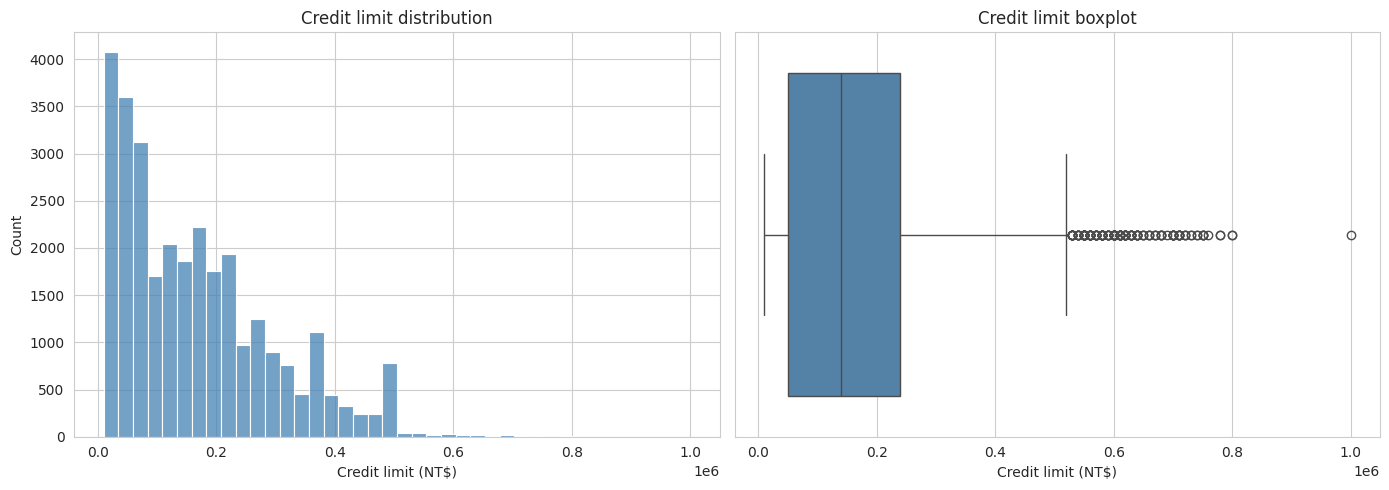

In [4]:
#  credit limit distribution

print("LIMIT_BAL summary")
print(df["LIMIT_BAL"].describe().round(0))
print("Skewness:", round(df["LIMIT_BAL"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["LIMIT_BAL"], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Credit limit distribution")
axes[0].set_xlabel("Credit limit (NT$)")

sns.boxplot(x=df["LIMIT_BAL"], ax=axes[1], color="steelblue")
axes[1].set_title("Credit limit boxplot")
axes[1].set_xlabel("Credit limit (NT$)")

plt.tight_layout()
plt.show()

                       customers  default_rate
LIMIT_band                                    
(9999.999, 50000.0]         7676         0.318
(50000.0, 100000.0]         4822         0.258
(100000.0, 180000.0]        6123         0.199
(180000.0, 270000.0]        5421         0.169
(270000.0, 1000000.0]       5958         0.138


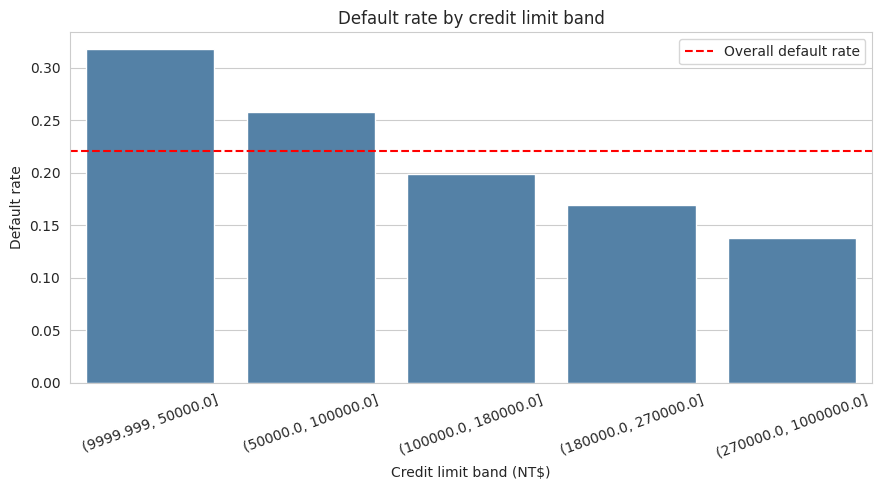


                        mean    median
default_next_month                    
0                   178100.0  150000.0
1                   130110.0   90000.0


In [5]:
#  default rate by credit limit band

# 1. Five bands with (roughly) equal numbers of customers
df["LIMIT_band"] = pd.qcut(df["LIMIT_BAL"], q=5, duplicates="drop")

limit_summary = df.groupby("LIMIT_band", observed=True)[target].agg(["count", "mean"]).round(3)
limit_summary.columns = ["customers", "default_rate"]
print(limit_summary)

# 2. Chart
plt.figure(figsize=(9, 5))
sns.barplot(x=limit_summary.index.astype(str), y=limit_summary["default_rate"], color="steelblue")
plt.axhline(df[target].mean(), color="red", linestyle="--", label="Overall default rate")
plt.title("Default rate by credit limit band")
plt.xlabel("Credit limit band (NT$)")
plt.ylabel("Default rate")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Average credit limit: defaulters vs non-defaulters
print()
print(df.groupby(target)["LIMIT_BAL"].agg(["mean", "median"]).round(0))

## EDA Finding 2: Credit limits

- LIMIT_BAL is right-skewed (skewness 0.99): median NT$140,000, mean NT$167,484. Half of customers have limits between 50,000 and 240,000.
- Default rate decreases steadily as the credit limit increases: 31.8% in the lowest band (up to 50,000) down to 13.8% in the highest band (above 270,000).
- Defaulters have lower limits on average (mean 130,110, median 90,000) than non-defaulters (mean 178,100, median 150,000).
- Note: this is an association, not a cause. Banks likely assigned lower limits to customers they considered riskier.

    PAY_1  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
-2  0.132  0.183  0.185  0.193  0.197  0.200
-1  0.168  0.160  0.156  0.159  0.162  0.170
 0  0.128  0.159  0.175  0.183  0.189  0.188
 1  0.339    NaN    NaN    NaN    NaN    NaN
 2  0.691  0.556  0.516  0.523  0.542  0.507
 3  0.758  0.617  0.575  0.611  0.635  0.641
 4    NaN    NaN    NaN    NaN    NaN    NaN
 5    NaN    NaN    NaN    NaN    NaN    NaN
 6    NaN    NaN    NaN    NaN    NaN    NaN
 7    NaN    NaN    NaN    NaN    NaN    NaN
 8    NaN    NaN    NaN    NaN    NaN    NaN


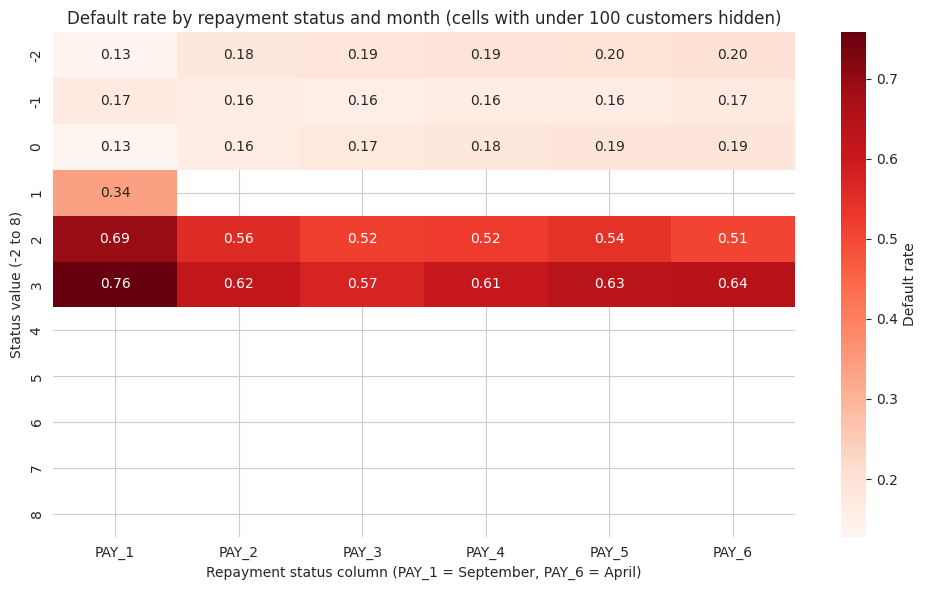

In [6]:
#  default rate by repayment status, for each of the six months

# Default rate for each status value, per month
rates = pd.DataFrame({c: df.groupby(c)[target].mean() for c in pay_cols})

# Number of customers behind each cell
counts = pd.DataFrame({c: df[c].value_counts() for c in pay_cols})
counts = counts.reindex(rates.index).fillna(0)

# Hide cells with fewer than 100 customers (unreliable)
rates_masked = rates.where(counts >= 100)

print(rates_masked.round(3))

plt.figure(figsize=(10, 6))
sns.heatmap(rates_masked, annot=True, fmt=".2f", cmap="Reds",
            cbar_kws={"label": "Default rate"})
plt.title("Default rate by repayment status and month (cells with under 100 customers hidden)")
plt.xlabel("Repayment status column (PAY_1 = September, PAY_6 = April)")
plt.ylabel("Status value (-2 to 8)")
plt.tight_layout()
plt.show()

## EDA Finding 3: Repayment history

- Repayment status is strongly associated with default. Customers with status -2, -1 or 0 (no consumption, paid on time, or paying minimum) default at only 13-20% in every month.
- Default rises sharply with delay: 1 month late = 33.9% (PAY_1), 2 months late = 51-69%, 3 months late = 57-76%.
- The most recent month (PAY_1, September) is the strongest signal: 2 months late = 69% and 3 months late = 76%, compared with 51-64% when the same delay appears in older months.
- Status values 4-8 have fewer than 100 customers in every month, so their rates are too unreliable to interpret. The value 1 is only common in PAY_1 (recording inconsistency noted in cleaning log entry 4).

             customers  default_rate
months_late                         
0                19931         0.117
1                 4426         0.298
2                 1899         0.388
3                 1154         0.509
4                  951         0.573
5                  298         0.574
6                 1341         0.703


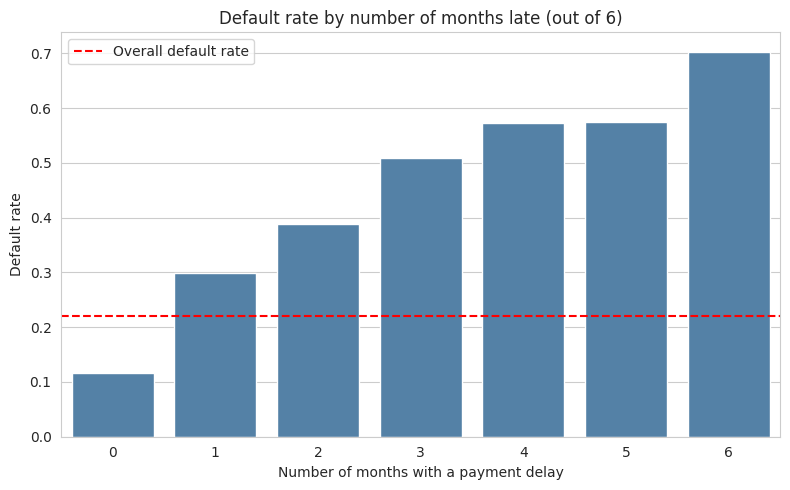

In [7]:
#  number of months late vs default rate

df["months_late"] = (df[pay_cols] >= 1).sum(axis=1)

late_summary = df.groupby("months_late")[target].agg(["count", "mean"]).round(3)
late_summary.columns = ["customers", "default_rate"]
print(late_summary)

plt.figure(figsize=(8, 5))
sns.barplot(x=late_summary.index, y=late_summary["default_rate"], color="steelblue")
plt.axhline(df[target].mean(), color="red", linestyle="--", label="Overall default rate")
plt.title("Default rate by number of months late (out of 6)")
plt.xlabel("Number of months with a payment delay")
plt.ylabel("Default rate")
plt.legend()
plt.tight_layout()
plt.show()

## EDA Finding 4: Number of months late

- 66.4% of customers (19,931) were never late in any of the six months; their default rate is only 11.7%.
- Default rate rises with each additional late month: 1 month = 29.8%, 2 = 38.8%, 3 = 50.9%, 4 = 57.3%, 5 = 57.4%, 6 = 70.3%.
- Customers late in all six months default about six times as often as customers never late.
- The 5-month group is small (298 customers), so the near-identical rates for 4 and 5 months are likely noise. The overall upward trend is clear.
- The count only includes delays of 1+ months and may slightly undercount lateness in older months because of the PAY_1 recording quirk (cleaning log entry 4).
- This count is a candidate engineered feature for the modelling phase.

MEAN bill and payment amounts
default_next_month        0        1
BILL_AMT1           51994.0  48509.0
BILL_AMT2           49717.0  47284.0
BILL_AMT3           47533.0  45182.0
BILL_AMT4           43611.0  42037.0
BILL_AMT5           40530.0  39540.0
BILL_AMT6           39042.0  38271.0
PAY_AMT1             6307.0   3397.0
PAY_AMT2             6640.0   3389.0
PAY_AMT3             5753.0   3367.0
PAY_AMT4             5301.0   3156.0
PAY_AMT5             5248.0   3219.0
PAY_AMT6             5719.0   3441.0

MEDIAN bill and payment amounts
default_next_month        0        1
BILL_AMT1           23120.0  20185.0
BILL_AMT2           21660.0  20300.0
BILL_AMT3           20202.0  19834.0
BILL_AMT4           19000.0  19120.0
BILL_AMT5           17998.0  18478.0
BILL_AMT6           16679.0  18028.0
PAY_AMT1             2460.0   1636.0
PAY_AMT2             2248.0   1534.0
PAY_AMT3             2000.0   1222.0
PAY_AMT4             1734.0   1000.0
PAY_AMT5             1765.0   1000.0
PAY_AMT6    

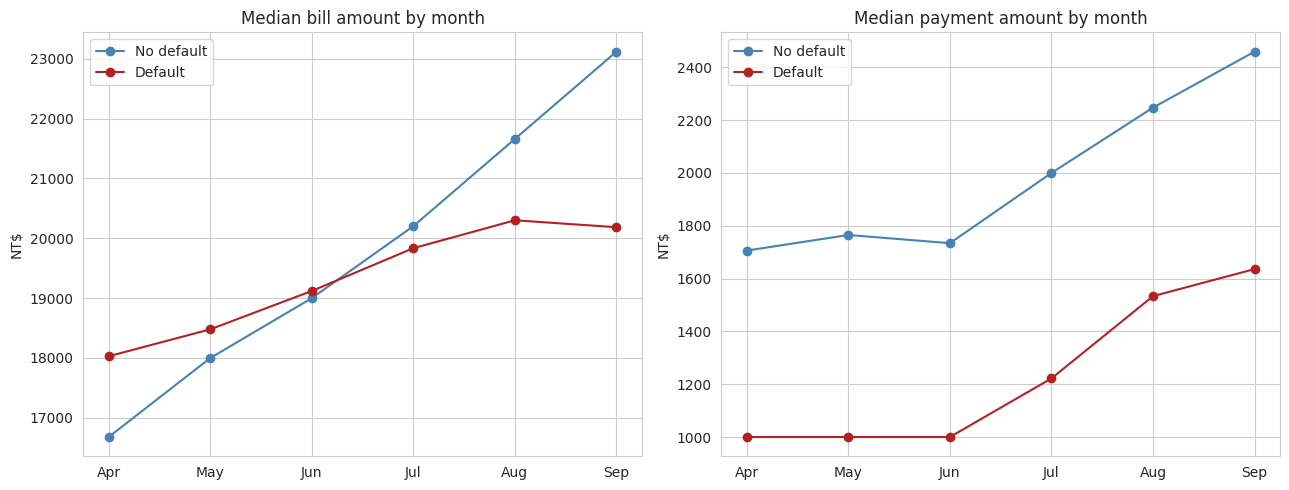

In [8]:
#  bills and payments, defaulters vs non-defaulters

# 1. Tables: mean and median per month, by group
print("MEAN bill and payment amounts")
print(df.groupby(target)[bill_cols + payamt_cols].mean().round(0).T)

print("\nMEDIAN bill and payment amounts")
print(df.groupby(target)[bill_cols + payamt_cols].median().round(0).T)

# 2. Chart: median bill and median payment over time, by group
# Months are listed oldest (6 = April) to newest (1 = September)
months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep"]
bill_order = bill_cols[::-1]      # BILL_AMT6 ... BILL_AMT1
pay_order = payamt_cols[::-1]     # PAY_AMT6 ... PAY_AMT1

med_bill = df.groupby(target)[bill_order].median()
med_pay = df.groupby(target)[pay_order].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for label, name, color in [(0, "No default", "steelblue"), (1, "Default", "firebrick")]:
    axes[0].plot(months, med_bill.loc[label].values, marker="o", label=name, color=color)
    axes[1].plot(months, med_pay.loc[label].values, marker="o", label=name, color=color)

axes[0].set_title("Median bill amount by month")
axes[0].set_ylabel("NT$")
axes[0].legend()

axes[1].set_title("Median payment amount by month")
axes[1].set_ylabel("NT$")
axes[1].legend()

plt.tight_layout()
plt.show()

## EDA Finding 5: Bills and payments

- Bill amounts are similar for defaulters and non-defaulters. Mean September bill: 51,994 (no default) vs 48,509 (default); medians are close in every month and sometimes higher for defaulters (April: 18,028 vs 16,679).
- Payment amounts differ clearly. Non-defaulters' median payment is about 1.5-1.8 times higher than defaulters' in every month (e.g. September: 2,460 vs 1,636; June: 1,734 vs 1,000). Mean payments show the same gap (about 1.6-2.0 times).
- Conclusion: how much a customer owes does not separate the two groups much; how much they pay does. A payment-to-bill ratio is a candidate engineered feature for modelling.
- Medians were used alongside means because bill and payment amounts are strongly right-skewed. In the charts, defaulters' median payment is exactly 1,000 in April, May and June (a very common round amount). By September non-defaulters' median bill (23,120) is higher than defaulters' (20,185), but the gap is small compared with the payment gap. Chart axes do not start at zero, so visual gaps look larger than they are.

Customers with a valid ratio: 28488 of 30000

Median payment ratio by group:
default_next_month
0    0.133
1    0.062
Name: pay_ratio, dtype: float64

Average number of months with zero payment, by group:
default_next_month
0    1.08
1    1.76
Name: zero_pay_months, dtype: float64

              customers  default_rate
ratio_band                           
Paid nothing        227         0.727
0-5%               8380         0.274
5-20%              7925         0.242
20-100%            8762         0.164
Over 100%          3194         0.113


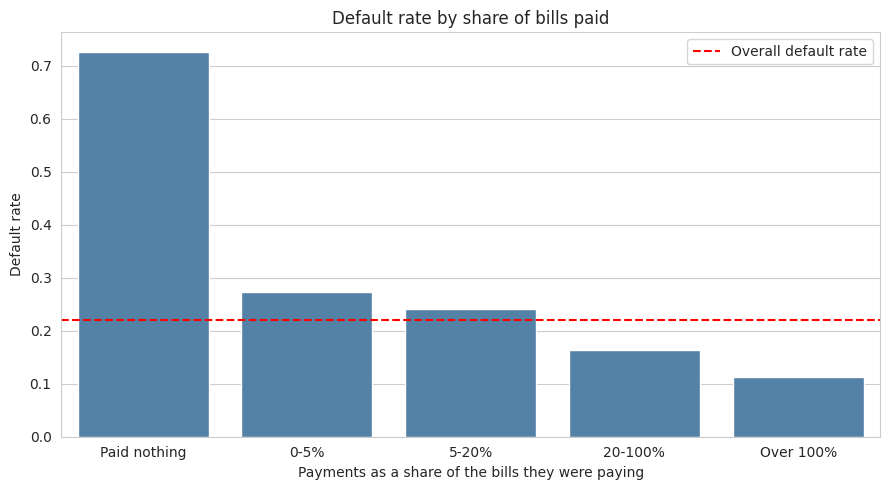

In [9]:
#  payment ratio and months with no payment

# Payments (Sep..May) vs the bills they were paying (Aug..Apr)
payments = df[["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5"]].sum(axis=1)
prev_bills = df[["BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]].sum(axis=1)

df["pay_ratio"] = (payments / prev_bills).where(prev_bills > 0)
df["zero_pay_months"] = (df[payamt_cols] == 0).sum(axis=1)

print("Customers with a valid ratio:", df["pay_ratio"].notna().sum(), "of", len(df))

# 1. Group comparison
print("\nMedian payment ratio by group:")
print(df.groupby(target)["pay_ratio"].median().round(3))
print("\nAverage number of months with zero payment, by group:")
print(df.groupby(target)["zero_pay_months"].mean().round(2))

# 2. Default rate by payment ratio band
bins = [-0.001, 0, 0.05, 0.2, 1, np.inf]
labels = ["Paid nothing", "0-5%", "5-20%", "20-100%", "Over 100%"]
df["ratio_band"] = pd.cut(df["pay_ratio"], bins=bins, labels=labels)

ratio_summary = df.groupby("ratio_band", observed=True)[target].agg(["count", "mean"]).round(3)
ratio_summary.columns = ["customers", "default_rate"]
print()
print(ratio_summary)

plt.figure(figsize=(9, 5))
sns.barplot(x=ratio_summary.index.astype(str), y=ratio_summary["default_rate"], color="steelblue")
plt.axhline(df[target].mean(), color="red", linestyle="--", label="Overall default rate")
plt.title("Default rate by share of bills paid")
plt.xlabel("Payments as a share of the bills they were paying")
plt.ylabel("Default rate")
plt.legend()
plt.tight_layout()
plt.show()

## EDA Finding 6: Payment relative to bills

- Defined pay_ratio = payments (September-May) / the bills they were paying (August-April). Calculated for 28,488 of 30,000 customers; 1,512 (5%) were excluded because their bills total zero or less.
- Median share of bills paid: 13.3% (no default) vs 6.2% (default).
- Defaulters averaged 1.76 months with zero payment (out of 6) vs 1.08 for non-defaulters.
- Default rate falls as the share paid rises: paid nothing 72.7% (only 227 customers), 0-5% 27.4%, 5-20% 24.2%, 20-100% 16.4%, over 100% 11.3%.
- Payment behaviour separates defaulters from non-defaulters much more than bill size does (Finding 5). pay_ratio and zero_pay_months are candidate features for modelling.

age_group
           customers  default_rate
age_group                         
21-29           9618         0.228
30-39          11238         0.203
40-49           6464         0.230
50-59           2341         0.249
60-79            339         0.283 

SEX_label
           customers  default_rate
SEX_label                         
Female         18112         0.208
Male           11888         0.242 

EDUCATION_label
                 customers  default_rate
EDUCATION_label                         
Graduate school      10585         0.192
High school           4917         0.252
Others                 468         0.071
University           14030         0.237 

MARRIAGE_label
                customers  default_rate
MARRIAGE_label                         
Married             13659         0.235
Others                323         0.260
Single              15964         0.209
Unknown                54         0.093 



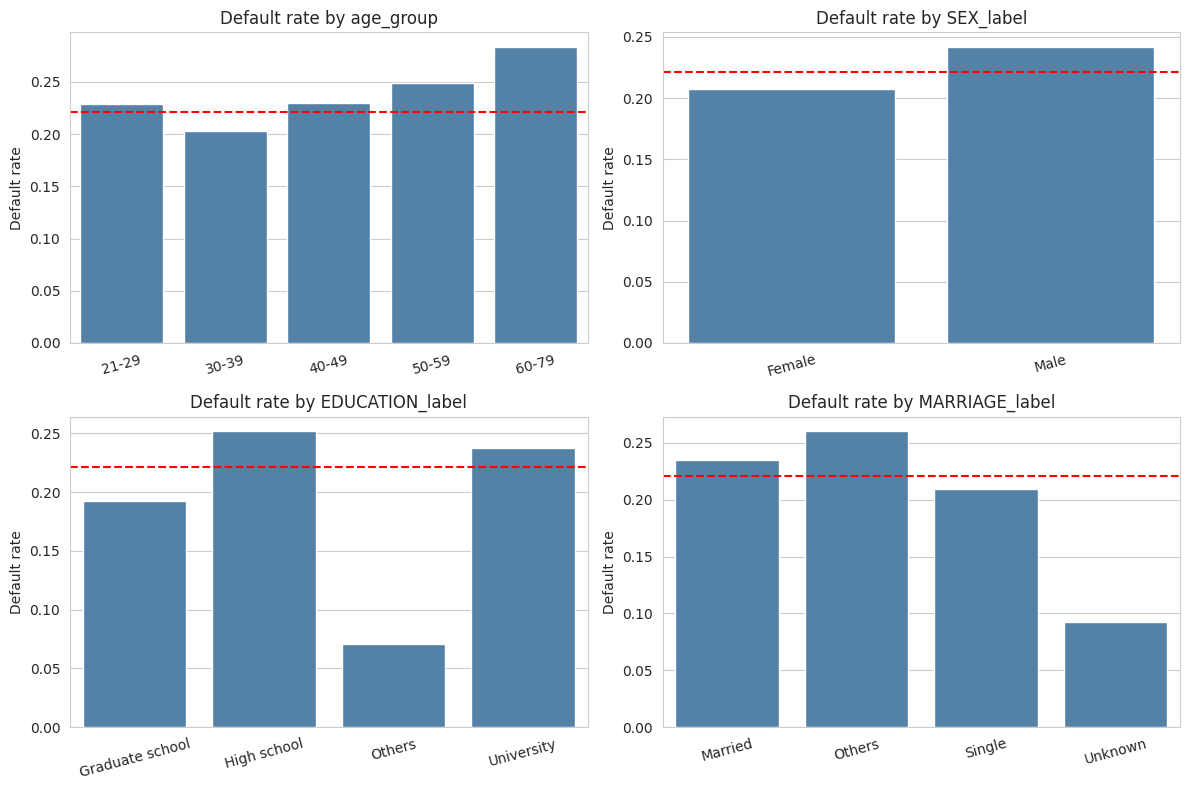

In [10]:
#  default rate by customer group

df["age_group"] = pd.cut(df["AGE"], bins=[20, 29, 39, 49, 59, 79],
                         labels=["21-29", "30-39", "40-49", "50-59", "60-79"])

group_cols = ["age_group", "SEX_label", "EDUCATION_label", "MARRIAGE_label"]

# 1. Tables: customers and default rate per group
for col in group_cols:
    t = df.groupby(col, observed=True)[target].agg(["count", "mean"]).round(3)
    t.columns = ["customers", "default_rate"]
    print(col)
    print(t, "\n")

# 2. Charts
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
overall = df[target].mean()

for ax, col in zip(axes.flatten(), group_cols):
    t = df.groupby(col, observed=True)[target].mean()
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax, color="steelblue")
    ax.axhline(overall, color="red", linestyle="--")
    ax.set_title(f"Default rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [11]:

for col in ["age_group", "SEX_label"]:
    t = df.groupby(col, observed=True)[target].agg(["count", "mean"]).round(3)
    t.columns = ["customers", "default_rate"]
    print(col)
    print(t, "\n")

age_group
           customers  default_rate
age_group                         
21-29           9618         0.228
30-39          11238         0.203
40-49           6464         0.230
50-59           2341         0.249
60-79            339         0.283 

SEX_label
           customers  default_rate
SEX_label                         
Female         18112         0.208
Male           11888         0.242 



## EDA Finding 7: Default rate by customer group

- Age: default rate is lowest for ages 30-39 (20.3%) and rises with age: 40-49 = 23.0%, 50-59 = 24.9%, 60-79 = 28.3%. Ages 21-29 are at 22.8%. The 60-79 group is small (339 customers, 1.1%), so its rate is imprecise.
- Gender: men 24.2% vs women 20.8% (gap of 3.4 points).
- Education: graduate school 19.2%, university 23.7%, high school 25.2%. "Others" (7.1%, 468 customers) is small.
- Marital status: married 23.5%, single 20.9%, others 26.0%. "Unknown" (9.3%, 54 customers) is too small to interpret.
- All demographic gaps (up to about 8 points for age) are much smaller than the gaps for repayment history (11.7% to 70.3%) and credit limit (13.8% to 31.8%). Whether the demographic differences are statistically significant is tested in Activity 8.

months_late        0.398
PAY_1              0.325
PAY_2              0.264
PAY_3              0.235
PAY_4              0.217
PAY_5              0.204
PAY_6              0.187
zero_pay_months    0.163
LIMIT_BAL         -0.154
PAY_AMT1          -0.073
PAY_AMT2          -0.059
PAY_AMT4          -0.057
PAY_AMT3          -0.056
PAY_AMT5          -0.055
PAY_AMT6          -0.053
SEX               -0.040
EDUCATION          0.034
MARRIAGE          -0.024
BILL_AMT1         -0.020
pay_ratio         -0.020
BILL_AMT2         -0.014
BILL_AMT3         -0.014
AGE                0.014
BILL_AMT4         -0.010
BILL_AMT5         -0.007
BILL_AMT6         -0.005
Name: default_next_month, dtype: float64


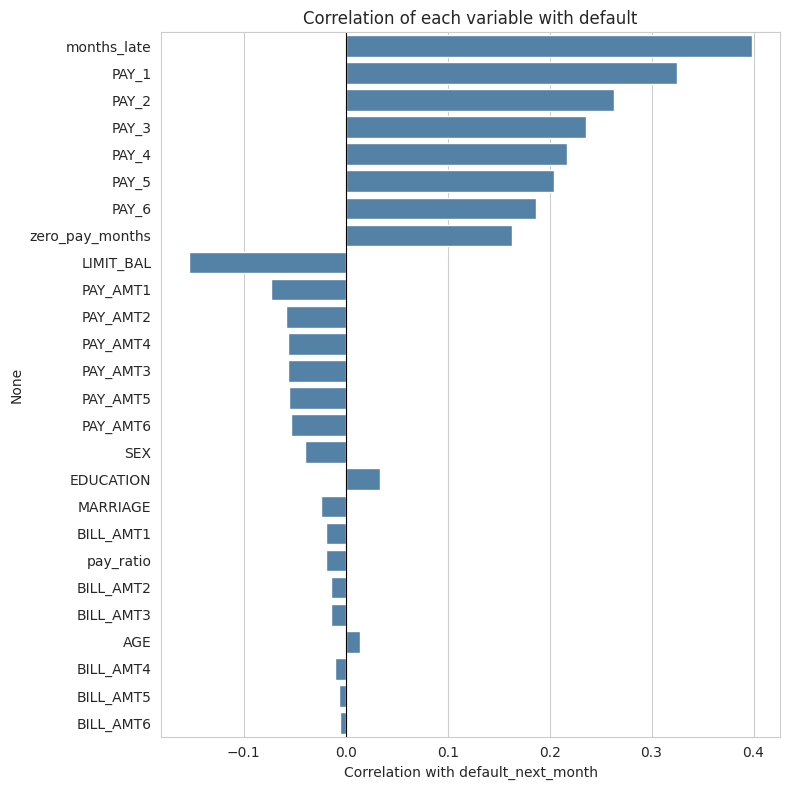

In [12]:
# correlation of every numeric variable with the target

num_for_corr = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"] + pay_cols + bill_cols + payamt_cols \
               + ["months_late", "zero_pay_months", "pay_ratio"]

corr_target = df[num_for_corr + [target]].corr(numeric_only=True)[target].drop(target)
corr_target = corr_target.sort_values(key=abs, ascending=False)

print(corr_target.round(3))

plt.figure(figsize=(8, 8))
sns.barplot(x=corr_target.values, y=corr_target.index, color="steelblue")
plt.title("Correlation of each variable with default")
plt.xlabel("Correlation with default_next_month")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## EDA Finding 8: Correlation with default

- Strongest correlations with default_next_month: months_late 0.398 (engineered), PAY_1 0.325, PAY_2 0.264, PAY_3 0.235, PAY_4 0.217, PAY_5 0.204, PAY_6 0.187, zero_pay_months 0.163.
- LIMIT_BAL is negative (-0.154): higher limits go with lower default. It is the strongest non-repayment variable.
- Payment amounts have weak negative correlations (-0.053 to -0.073). Bill amounts (-0.020 to -0.005) and demographics (|r| < 0.04) are close to zero.
- Repayment status is most strongly related to default, and the most recent month (PAY_1) is the strongest of the six.
- Caution: Pearson correlation only captures linear relationships. AGE (r = 0.014) and pay_ratio (r = -0.020) have clear non-linear patterns shown in Findings 6 and 7 that correlation understates. Correlations for category codes (SEX, EDUCATION, MARRIAGE) are only loosely meaningful.

Average correlation between columns of the same group:
  BILL_AMT1-6 : 0.89
  PAY_1-6     : 0.66
  PAY_AMT1-6  : 0.19

BILL_AMT1 vs BILL_AMT2: 0.95
BILL_AMT1 vs BILL_AMT6: 0.8


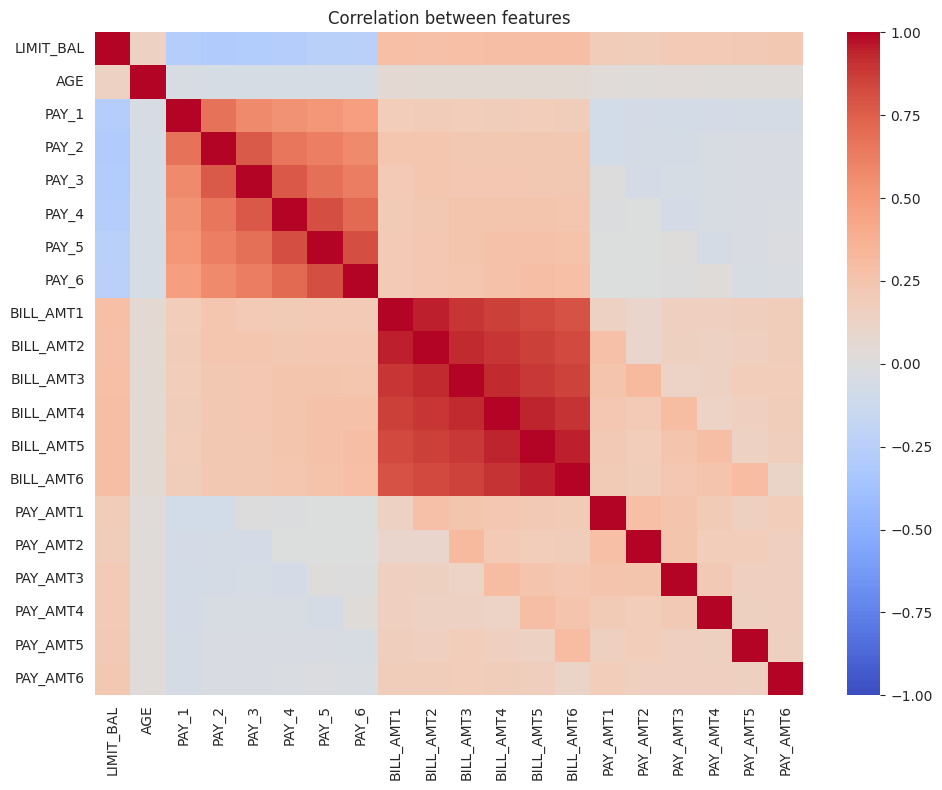

In [13]:
# correlations among the features themselves

feature_cols = ["LIMIT_BAL", "AGE"] + pay_cols + bill_cols + payamt_cols
corr_matrix = df[feature_cols].corr()

# Average correlation between different columns within each group
def avg_offdiag(cols):
    m = df[cols].corr().values
    return m[np.triu_indices_from(m, k=1)].mean()

print("Average correlation between columns of the same group:")
print("  BILL_AMT1-6 :", round(avg_offdiag(bill_cols), 2))
print("  PAY_1-6     :", round(avg_offdiag(pay_cols), 2))
print("  PAY_AMT1-6  :", round(avg_offdiag(payamt_cols), 2))

# Correlation between neighbouring bill months
print("\nBILL_AMT1 vs BILL_AMT2:", round(df["BILL_AMT1"].corr(df["BILL_AMT2"]), 2))
print("BILL_AMT1 vs BILL_AMT6:", round(df["BILL_AMT1"].corr(df["BILL_AMT6"]), 2))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

## EDA Finding 9: Relationships among the features (multicollinearity)

- BILL_AMT1-6 are highly correlated with each other (average r = 0.89; September vs August r = 0.95; September vs April r = 0.80). A customer's bill barely changes from month to month.
- PAY_1-6 are strongly correlated (average r = 0.66): a customer late in one month tends to be late in neighbouring months.
- PAY_AMT1-6 are only weakly related to each other (average r = 0.19), so each month's payment carries fairly independent information.
- LIMIT_BAL is negatively correlated with the repayment status columns (higher limit goes with better status). AGE is weakly related to all other features.
- Modelling implication: the strong overlap among bill columns will make Logistic Regression coefficients unstable. We plan summary features (e.g. average bill) and regularisation in Phase 6. Tree-based models are less affected, but their feature importance will be split across the correlated columns.

In [14]:
# descriptive statistics

# 1. Overall summary for the main numeric variables
main_num = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "months_late", "zero_pay_months"]

desc = df[main_num].agg(["mean", "median", "std", "min", "max", "skew"]).T.round(2)
print("Overall descriptive statistics")
print(desc)

# 2. Same variables, split by default status (mean and median)
print("\nBy default status (mean)")
print(df.groupby(target)[main_num].mean().T.round(1))

print("\nBy default status (median)")
print(df.groupby(target)[main_num].median().T.round(1))

# 3. Coefficient of variation: spread relative to the mean
cv = (df[main_num].std() / df[main_num].mean()).round(2)
print("\nCoefficient of variation (std / mean)")
print(cv)

Overall descriptive statistics
                      mean    median        std       min        max   skew
LIMIT_BAL        167484.32  140000.0  129747.66   10000.0  1000000.0   0.99
AGE                  35.49      34.0       9.22      21.0       79.0   0.73
BILL_AMT1         51223.33   22381.5   73635.86 -165580.0   964511.0   2.66
PAY_AMT1           5663.58    2100.0   16563.28       0.0   873552.0  14.67
months_late           0.83       0.0       1.55       0.0        6.0   2.13
zero_pay_months       1.23       0.0       1.72       0.0        6.0   1.45

By default status (mean)
default_next_month         0         1
LIMIT_BAL           178099.7  130109.7
AGE                     35.4      35.7
BILL_AMT1            51994.2   48509.2
PAY_AMT1              6307.3    3397.0
months_late              0.5       2.0
zero_pay_months          1.1       1.8

By default status (median)
default_next_month         0        1
LIMIT_BAL           150000.0  90000.0
AGE                     34.0     3

## EDA Finding 10: Descriptive statistics

- Amount variables are strongly right-skewed. PAY_AMT1: mean 5,664 vs median 2,100, skewness 14.67. BILL_AMT1: mean 51,223 vs median 22,382, skewness 2.66. LIMIT_BAL (skewness 0.99) and AGE (0.73) are mildly skewed. Medians describe the typical customer better than means for these variables.
- months_late and zero_pay_months have median 0: most customers were never late and never skipped a payment.
- Most unevenly distributed (coefficient of variation): PAY_AMT1 2.92, months_late 1.86, BILL_AMT1 1.44, zero_pay_months 1.40, LIMIT_BAL 0.77, AGE 0.26.
- Defaulters vs non-defaulters (mean): months_late 2.0 vs 0.5, LIMIT_BAL 130,110 vs 178,100, PAY_AMT1 3,397 vs 6,307, zero_pay_months 1.8 vs 1.1. AGE (35.7 vs 35.4) and BILL_AMT1 (48,509 vs 51,994) differ little.
- Modelling implication: skewed amount columns call for scaling and possibly log transformation for Logistic Regression; tree models are unaffected.

In [15]:
#  chi-square tests of independence with the target
from scipy.stats import chi2_contingency

def chi_square_test(col):
    table = pd.crosstab(df[col], df[target])
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return {"variable": col, "chi2": round(chi2, 1), "dof": dof,
            "p_value": p, "cramers_v": round(cramers_v, 3),
            "min_expected_count": round(expected.min(), 1)}

cat_vars = ["SEX_label", "EDUCATION_label", "MARRIAGE_label", "age_group", "PAY_1"]
results = pd.DataFrame([chi_square_test(c) for c in cat_vars])
results["p_value"] = results["p_value"].apply(lambda x: f"{x:.2e}")
results

,variable,chi2,dof,p_value,cramers_v,min_expected_count
0,SEX_label,47.7,1,4.94e-12,0.040,2629.6
1,EDUCATION_label,160.4,3,1.50e-34,0.073,103.5
2,MARRIAGE_label,35.7,3,8.83e-08,0.034,11.9
3,age_group,46.2,4,2.28e-09,0.039,75.0
4,PAY_1,5366.0,10,0.00e+00,0.423,2.0


In [16]:

df["PAY_1_grouped"] = pd.cut(df["PAY_1"], bins=[-3, 0, 1, 2, 8],
                             labels=["On time / no use (-2 to 0)", "1 month late",
                                     "2 months late", "3+ months late"])

print(chi_square_test("PAY_1_grouped"))
print()
print(df.groupby("PAY_1_grouped", observed=True)[target].agg(["count", "mean"]).round(3))

{'variable': 'PAY_1_grouped', 'chi2': np.float64(5313.0), 'dof': 3, 'p_value': np.float64(0.0), 'cramers_v': np.float64(0.421), 'min_expected_count': np.float64(102.4)}

                            count   mean
PAY_1_grouped                           
On time / no use (-2 to 0)  23182  0.138
1 month late                 3688  0.339
2 months late                2667  0.691
3+ months late                463  0.719


## EDA Finding 11: Chi-square tests of independence (categorical variables vs default)

- All five tested variables are significantly associated with default (all p < 0.001), but the strength differs enormously (Cramér's V):
  - SEX: V = 0.040 (weak)
  - MARRIAGE: V = 0.034 (weak)
  - age_group: V = 0.039 (weak)
  - EDUCATION: V = 0.073 (weak)
  - PAY_1 (repayment status): V = 0.423 (strong)
- With 30,000 customers even tiny differences are statistically significant, so effect size (Cramér's V) is more informative than the p-value. Demographics are real but weak signals; repayment status is a strong one.
- The original PAY_1 test had a minimum expected count of 2.0 (below the guideline of 5) because of very small status groups. Rerunning with grouped statuses (on time/no use, 1 month late, 2 months late, 3+ months late) gave a valid test (minimum expected count 102.4) and the same result: V = 0.421, p < 0.001.
- Default rate by grouped PAY_1: on time/no use 13.8%, 1 month late 33.9%, 2 months late 69.1%, 3+ months late 71.9%.

In [17]:
# Mann-Whitney U tests, defaulters vs non-defaulters
from scipy.stats import mannwhitneyu

def mw_test(col):
    d = df.loc[df[target] == 1, col].dropna()   # defaulters
    nd = df.loc[df[target] == 0, col].dropna()  # non-defaulters
    u, p = mannwhitneyu(d, nd, alternative="two-sided")
    r = 2 * u / (len(d) * len(nd)) - 1          # rank-biserial correlation
    return {"variable": col,
            "median_default": d.median(),
            "median_no_default": nd.median(),
            "effect_size_r": round(r, 3),
            "p_value": f"{p:.2e}"}

num_tests = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2",
             "months_late", "zero_pay_months", "pay_ratio"]

mw_results = pd.DataFrame([mw_test(c) for c in num_tests])
mw_results

,variable,median_default,median_no_default,effect_size_r,p_value
0,LIMIT_BAL,90000.000000,150000.000000,-0.236,1.23e-189
1,AGE,34.000000,34.000000,0.007,3.73e-01
2,BILL_AMT1,20185.000000,23119.500000,-0.035,1.15e-05
3,PAY_AMT1,1636.000000,2459.500000,-0.223,4.62e-170
4,PAY_AMT2,1533.500000,2247.500000,-0.209,9.95e-151
5,months_late,1.000000,0.000000,0.452,0.00e+00
6,zero_pay_months,1.000000,0.000000,0.254,2.06e-256
7,pay_ratio,0.062088,0.132536,-0.217,7.71e-151


## EDA Finding 12: Mann-Whitney U tests (numeric variables, defaulters vs non-defaulters)

- Mann-Whitney U was used instead of the t-test because most variables are strongly skewed (Finding 10). Effect size = rank-biserial correlation (below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium, above 0.5 large; rough convention).
- months_late: r = +0.452 (medium); median 1 for defaulters vs 0 for non-defaulters, p < 0.001. The strongest numeric variable.
- Small effects (p < 0.001): zero_pay_months r = +0.254; LIMIT_BAL r = -0.236 (median 90,000 vs 150,000); PAY_AMT1 r = -0.223 (1,636 vs 2,460); pay_ratio r = -0.217 (median 0.062 vs 0.133); PAY_AMT2 r = -0.209.
- Negligible: BILL_AMT1 r = -0.035 (significant, p = 1.15e-5, but negligible) and AGE r = +0.007 (not significant, p = 0.373; identical medians of 34).
- All signs are consistent with earlier findings: defaulters have more late months and more zero-payment months, and lower limits, payments and payment ratios.
- AGE: the test finds no overall difference, yet default rates differ by age group (Finding 7, chi-square p < 0.001). The pattern is non-linear (lowest in the 30s, higher on both sides), which a rank test comparing the two groups as a whole cannot detect. Age has a weak, non-linear relationship with default.
- pay_ratio is much more informative here (r = -0.217) than its Pearson correlation (-0.020, Finding 8), because extreme

## Summary

1. Which age groups have higher default rates?
Ages 30-39 have the lowest rate (20.3%). Rates rise with age: 40-49 = 23.0%, 50-59 = 24.9%, 60-79 = 28.3% (only 339 customers, so imprecise). Ages 21-29 are at 22.8%. The relationship is statistically significant but weak (Cramér's V = 0.039) and non-linear (Findings 7, 11, 12).

2. Is default associated with repayment history?
Yes, strongly. This is the strongest relationship in the dataset. PAY_1 has Cramér's V = 0.423. Default is 13.8% for customers on time / not using the card, 33.9% for 1 month late and 69.1% for 2 months late. Customers never late in six months default at 11.7%, and those late in all six months at 70.3%. The most recent month matters most (Findings 3, 4, 8, 11).

3. Do customers with different credit limits show different default patterns?
Yes. Default falls from 31.8% (limit up to NT$50,000) to 13.8% (limit above NT$270,000). Correlation -0.154, effect size -0.236 (small). This is an association, not a cause: banks likely gave lower limits to riskier customers (Findings 2, 8, 12).

4. How do payment behaviours differ between defaulting and non-defaulting customers?
Defaulters pay less and skip payments more often. Median payment is about 1.5-1.8 times lower every month (e.g. September 1,636 vs 2,460). They paid a median 6.2% of the bills they were paying vs 13.3%, and averaged 1.76 months with no payment vs 1.08. Customers who paid nothing had a 72.7% default rate. Bill amounts barely differ between the groups (Findings 5, 6, 12).

5. Which variables appear most strongly associated with default?
Repayment status and history (months_late, PAY_1 to PAY_6, zero_pay_months) are strongest, followed by credit limit and payment behaviour (PAY_AMT columns, pay_ratio). Demographics (gender, education, marital status, age) are statistically significant but weak (V below 0.08). Bill amounts are negligible. Bill columns are highly correlated with each other (average r = 0.89), which matters for modelling (Findings 8, 9, 11, 12).